In [87]:
import pandas as pd; import numpy as np; import matplotlib.pyplot as plt; import seaborn as sns;
from sklearn.datasets import make_classification as mc;
from sklearn.metrics import precision_recall_curve as prc;
from sklearn.metrics import roc_curve as roc;
from sklearn.metrics import classification_report as report;
from sklearn.metrics import roc_auc_score;
from sklearn.linear_model import LogisticRegression as LR;
from sklearn.model_selection import train_test_split;
from sklearn.preprocessing import OneHotEncoder as OHE;
from sklearn.ensemble import RandomForestClassifier as RFC;
from sklearn.svm import SVC;
from sklearn.metrics import precision_score
from numpy import argmax
from sklearn.metrics import recall_score
from yellowbrick.classifier import ROCAUC
from yellowbrick.classifier import PrecisionRecallCurve

#1 Повторите анализ из лабораторной работы, но с двумерными датасетами. Изобразите графически, как изменение порога влияет на расположение границы принятия решений.

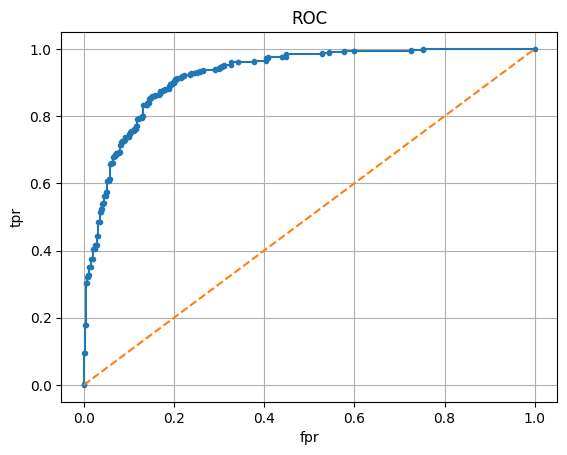

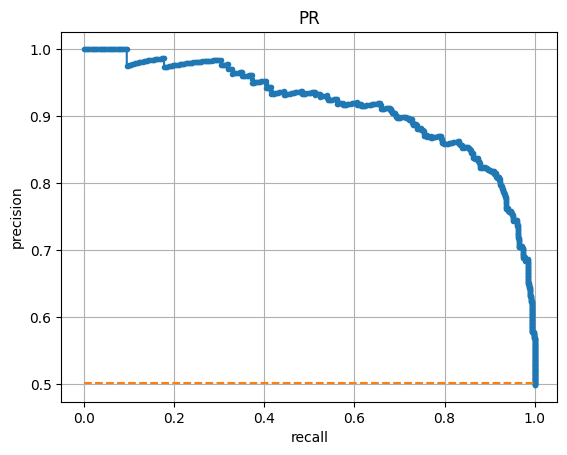


              precision    recall  f1-score   support

           0       0.87      0.81      0.84       401
           1       0.82      0.88      0.85       399

    accuracy                           0.85       800
   macro avg       0.85      0.85      0.85       800
weighted avg       0.85      0.85      0.85       800




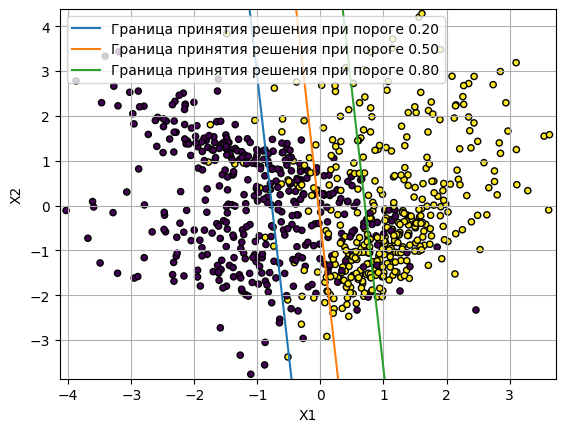

In [ ]:
# Создаем и учим модель
x,y = mc(n_features=2, n_redundant=0, n_samples=1000, n_classes=2, random_state=1)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.8, random_state=2)
m = LR().fit(x_train,y_train)
proba = m.predict_proba(x_test)

# Выводим ROC кривую
plt.title("ROC")
plt.xlabel("fpr")
plt.ylabel("tpr")
plt.grid('ON')
plt.plot(*roc(y_test, proba[:, 1])[:-1], marker='.')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.show()

print()

# Выводим PR кривую
plt.title("PR")
plt.grid('ON')
plt.xlabel("recall")
plt.ylabel("precision")
precision, recall = prc(y_test, proba[:, 1])[:-1]
plt.plot(recall,precision, marker='.')
no_skill = len(y[y==1]) / len(y)
plt.plot([0, 1], [no_skill, no_skill], linestyle='--')
plt.show()

print()

print(report(y_test,m.predict(x_test)))

print()

# Изобразим как изменение порога влияет на расположение границы принятия решений

def plot_decision_thresholds(model, X, y, thresholds=[0.2, 0.5, 0.8]):
    # Получаем параметры модели
    w0 = model.intercept_[0]
    w1, w2 = model.coef_[0]

    # Определяем границы графика
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1

    # Создаем сетку для первой фичи
    xx = np.linspace(x_min, x_max, 100)

    # Рисуем линии для каждого порога
    for threshold in thresholds:
        # Вычисляем z для заданного порога
        z = np.log(threshold / (1 - threshold))
        # Решаем уравнение w0 + w1*x + w2*y = z
        yy = (z - w0 - w1 * xx) / w2
        plt.plot(xx, yy, label=f'Граница принятия решения при пороге {threshold:.2f}')

    # Визуализируем данные
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', s=20)

    # Настройки графика
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.legend()
    plt.grid(True)
    plt.show()
plot_decision_thresholds(m,x_test,y_test)

#2 Повторите анализ на реальном датасете для бинарной классификации. Проинтерпретируйте результат, сделайте вывод.

In [ ]:
p = pd.read_csv('/content/heart_2020_cleaned.csv')
p2 = pd.get_dummies(p,columns = list(p.dtypes[p.dtypes != 'float64'].index.drop('HeartDisease')), dtype = np.float64)
p2['HeartDisease'] = p2['HeartDisease'].apply(lambda k: 1 if k=='Yes' else 0)
display(p.head())
display(p2.head())
#print(*list(p.columns),sep='\n')
p.info()
p2.info()
y = p2[['HeartDisease']]
x = p2.drop(['HeartDisease'],axis=1)
display(p2.describe())

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,White,Yes,Yes,Very good,5.0,Yes,No,Yes
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,White,No,Yes,Very good,7.0,No,No,No
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,White,Yes,Yes,Fair,8.0,Yes,No,No
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,White,No,No,Good,6.0,No,No,Yes
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,White,No,Yes,Very good,8.0,No,No,No


,HeartDisease,BMI,PhysicalHealth,MentalHealth,SleepTime,Smoking_No,Smoking_Yes,AlcoholDrinking_No,AlcoholDrinking_Yes,Stroke_No,...,GenHealth_Fair,GenHealth_Good,GenHealth_Poor,GenHealth_Very good,Asthma_No,Asthma_Yes,KidneyDisease_No,KidneyDisease_Yes,SkinCancer_No,SkinCancer_Yes
0,0,16.60,3.0,30.0,5.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
1,0,20.34,0.0,0.0,7.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
2,0,26.58,20.0,30.0,8.0,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
3,0,24.21,0.0,0.0,6.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
4,0,23.71,28.0,0.0,8.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319795 entries, 0 to 319794
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   HeartDisease      319795 non-null  object 
 1   BMI               319795 non-null  float64
 2   Smoking           319795 non-null  object 
 3   AlcoholDrinking   319795 non-null  object 
 4   Stroke            319795 non-null  object 
 5   PhysicalHealth    319795 non-null  float64
 6   MentalHealth      319795 non-null  float64
 7   DiffWalking       319795 non-null  object 
 8   Sex               319795 non-null  object 
 9   AgeCategory       319795 non-null  object 
 10  Race              319795 non-null  object 
 11  Diabetic          319795 non-null  object 
 12  PhysicalActivity  319795 non-null  object 
 13  GenHealth         319795 non-null  object 
 14  SleepTime         319795 non-null  float64
 15  Asthma            319795 non-null  object 
 16  KidneyDisease     31

,HeartDisease,BMI,PhysicalHealth,MentalHealth,SleepTime,Smoking_No,Smoking_Yes,AlcoholDrinking_No,AlcoholDrinking_Yes,Stroke_No,...,GenHealth_Fair,GenHealth_Good,GenHealth_Poor,GenHealth_Very good,Asthma_No,Asthma_Yes,KidneyDisease_No,KidneyDisease_Yes,SkinCancer_No,SkinCancer_Yes
count,319795.000000,319795.000000,319795.00000,319795.000000,319795.000000,319795.000000,319795.000000,319795.000000,319795.000000,319795.000000,...,319795.000000,319795.000000,319795.000000,319795.000000,319795.000000,319795.000000,319795.000000,319795.000000,319795.000000,319795.000000
mean,0.085595,28.325399,3.37171,3.898366,7.097075,0.587523,0.412477,0.931903,0.068097,0.962260,...,0.108435,0.291215,0.035301,0.356034,0.865939,0.134061,0.963167,0.036833,0.906756,0.093244
std,0.279766,6.356100,7.95085,7.955235,1.436007,0.492281,0.492281,0.251912,0.251912,0.190567,...,0.310930,0.454323,0.184539,0.478826,0.340718,0.340718,0.188352,0.188352,0.290775,0.290775
min,0.000000,12.020000,0.00000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,24.030000,0.00000,0.000000,6.000000,0.000000,0.000000,1.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
50%,0.000000,27.340000,0.00000,0.000000,7.000000,1.000000,0.000000,1.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
75%,0.000000,31.420000,2.00000,3.000000,8.000000,1.000000,1.000000,1.000000,0.000000,1.000000,...,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
max,1.000000,94.850000,30.00000,30.000000,24.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


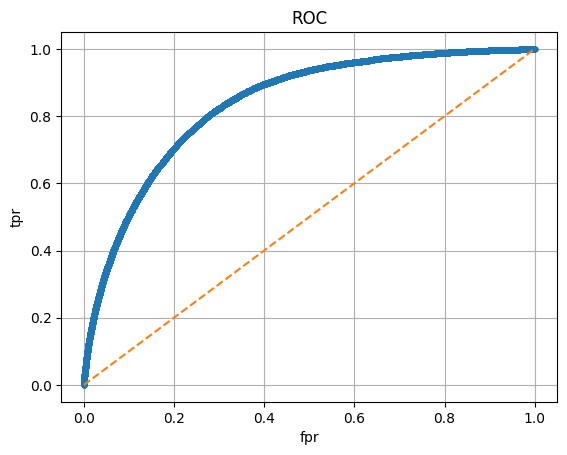

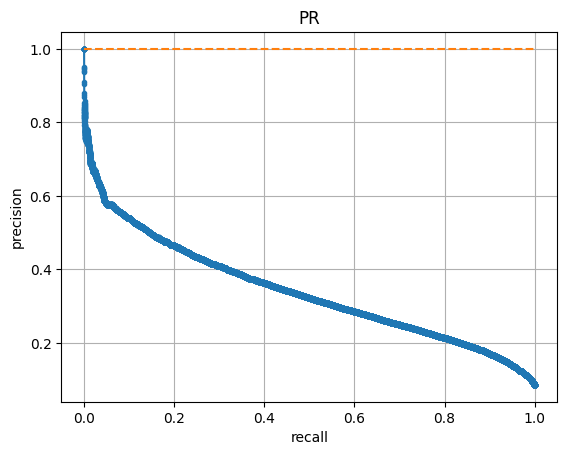


              precision    recall  f1-score   support

           0       0.92      0.99      0.96    263155
           1       0.53      0.11      0.19     24661

    accuracy                           0.92    287816
   macro avg       0.72      0.55      0.57    287816
weighted avg       0.89      0.92      0.89    287816




0.8371370504644912

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.9, random_state=2)
#m = RFC(n_estimators = 200).fit(x_train,y_train)
m = LR().fit(x_train,y_train)
#m = SVC(kernel = 'rbf', probability=True).fit(x_train,y_train)
proba = m.predict_proba(x_test)

# Выводим ROC кривую
plt.title("ROC")
plt.xlabel("fpr")
plt.ylabel("tpr")
plt.grid('ON')
plt.plot(*roc(y_test, proba[:, 1])[:-1], marker='.')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.show()

print()

# Выводим PR кривую
plt.title("PR")
plt.grid('ON')
plt.xlabel("recall")
plt.ylabel("precision")
precision, recall = prc(y_test, proba[:, 1])[:-1]
plt.plot(recall,precision, marker='.')
no_skill = len(y[y==1]) / len(y)
plt.plot([0, 1], [no_skill, no_skill], linestyle='--')
plt.show()

print()

print(report(y_test,m.predict(x_test)))

print()

roc_auc_score(y_test, proba[:, 1])

Вывод: несмотря на высокие показатели precision, recall в macro и weighted, высокий roc-auc, модель очень плохо выполняет свою функцию - обнаружение пациентов с проблемами сердца (recall класса 1).  
Это можно заметить ещё с кривой PR, где модель показывает явный дизбаланс метрик на разных значениях порога

#3 В задании по оптимизации порога используйте ROC и среднее геометрическое между TPR и FPR как критерий оптимизации.

порог: 0.07857717275756276
геометрическое среднее: 0.7614099751163417


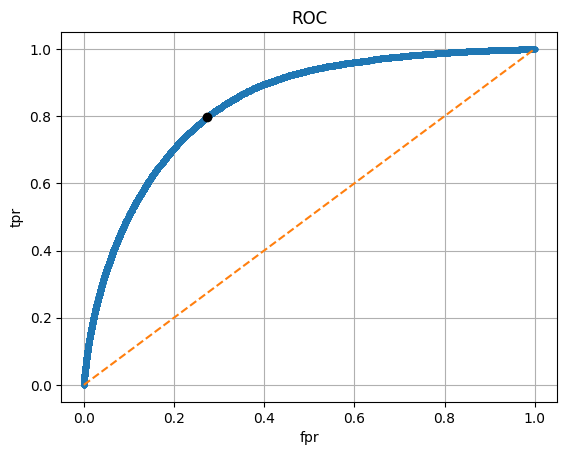

(0.27359540954950506, 0.7981022667369531)

In [ ]:
fpr, tpr, threshholds = roc(y_test, proba[:, 1])
gmean = np.sqrt(tpr * (1-fpr))
print(f'порог: {threshholds[argmax(gmean)]}\nгеометрическое среднее: {gmean[argmax(gmean)]}')
ind = argmax(gmean)

# Выводим ROC кривую
plt.title("ROC")
plt.xlabel("fpr")
plt.ylabel("tpr")
plt.grid('ON')
plt.plot(*roc(y_test, proba[:, 1])[:-1], marker='.')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.plot(fpr[ind],tpr[ind],marker='o',color='black')
plt.show()

fpr[ind],tpr[ind]

#4 При оптимизации порога по PR-кривой используйте другую F-метрику - сначала с преимуществом precision, а затем - с превалированием recall. Изобразите получившиеся пороги на графике. Проанализируйте метрики получившихся моделей.

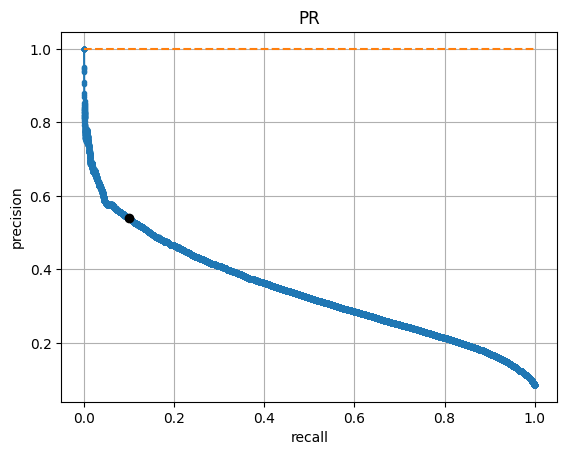

порог: 0.5240168362661363
f1: 0.49366014345614895
Bias: 0.15
Recall : [0.99194771 0.10117189]
Precision: [0.92173078 0.54074556]



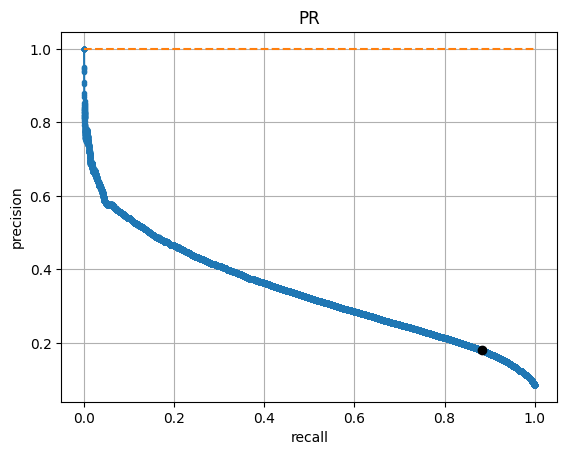

порог: 0.05155117595447386
f1: 0.6820796759265546
Bias: 3.5
Recall : [0.62156524 0.88394631]
Precision: [0.98280358 0.17958414]


In [ ]:
p, r, threshholds = prc(y_test, proba[:, 1])

beta = 0.15
f = (1 + beta**2) * (p*r) / (beta**2 * p + r)
ind = argmax(f)
# Выводим PR кривую
plt.title("PR")
plt.grid('ON')
plt.xlabel("recall")
plt.ylabel("precision")
precision, recall = prc(y_test, proba[:, 1])[:-1]
plt.plot(recall,precision, marker='.')
no_skill = len(y[y==1]) / len(y)
plt.plot([0, 1], [no_skill, no_skill], linestyle='--')
plt.plot(r[ind],p[ind],marker='o',color='black')
plt.show()
#print(report(y_test,np.where(proba[:, 1]>ind,1,0)))
print(f'порог: {threshholds[ind]}')
print(f'f1: {f[ind]}')
print(f'Bias: {beta}')
print(f'Recall : {recall_score(y_test.values.T[0], np.where(proba[:, 1]>threshholds[ind],1,0), average = None)}\nPrecision: {precision_score(y_test.values.T[0], np.where(proba[:, 1]>threshholds[ind],1,0), average = None)}')

print()



beta = 3.5
f = (1 + beta**2) * (p*r) / (beta**2 * p + r)
ind = argmax(f)
# Выводим PR кривую
plt.title("PR")
plt.grid('ON')
plt.xlabel("recall")
plt.ylabel("precision")
precision, recall = prc(y_test, proba[:, 1])[:-1]
plt.plot(recall,precision, marker='.')
no_skill = len(y[y==1]) / len(y)
plt.plot([0, 1], [no_skill, no_skill], linestyle='--')
plt.plot(r[ind],p[ind],marker='o',color='black')
plt.show()
#print(report(y_test,np.where(proba[:, 1]>ind,1,0)))
print(f'порог: {threshholds[ind]}')
print(f'f1: {f[ind]}')
print(f'Bias: {beta}')
print(f'Recall : {recall_score(y_test.values.T[0], np.where(proba[:, 1]>threshholds[ind],1,0), average = None)}\nPrecision: {precision_score(y_test.values.T[0], np.where(proba[:, 1]>threshholds[ind],1,0), average = None)}')

#5 Постройте классификационные кривые для задачи множественной классификации. Проинтерпретируйте результат.

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


/usr/local/lib/python3.11/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


0.9111111111111111
Класс: species_Iris-setosa


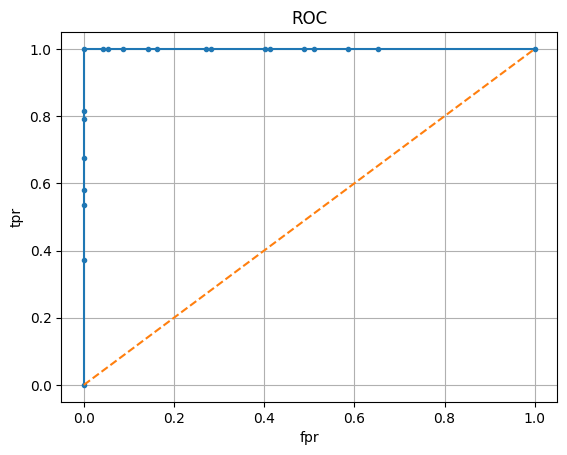

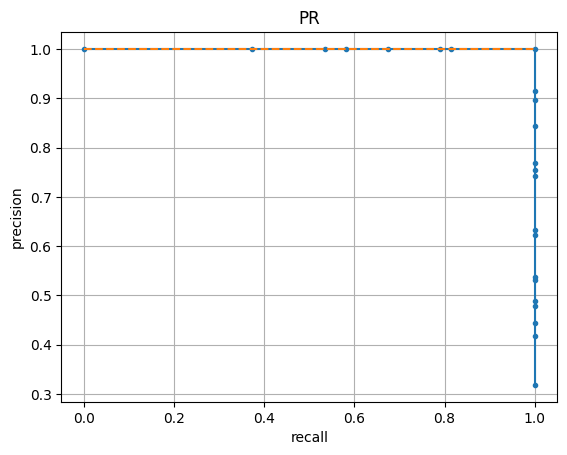


Класс: species_Iris-versicolor


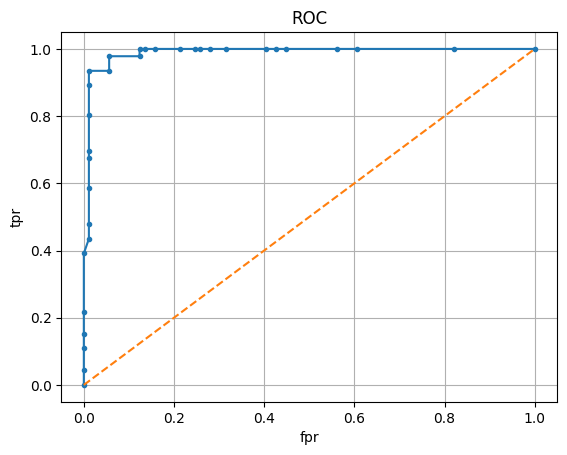

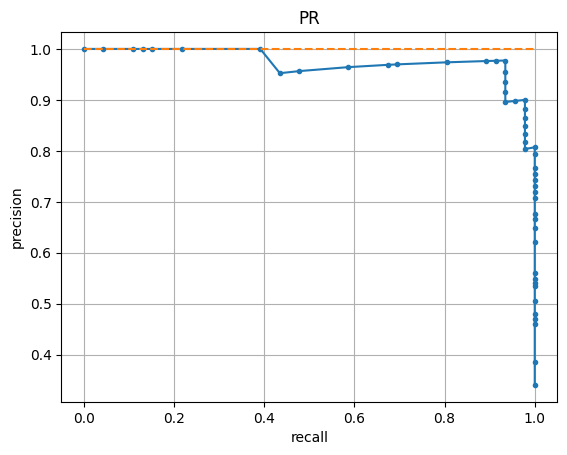


Класс: species_Iris-virginica


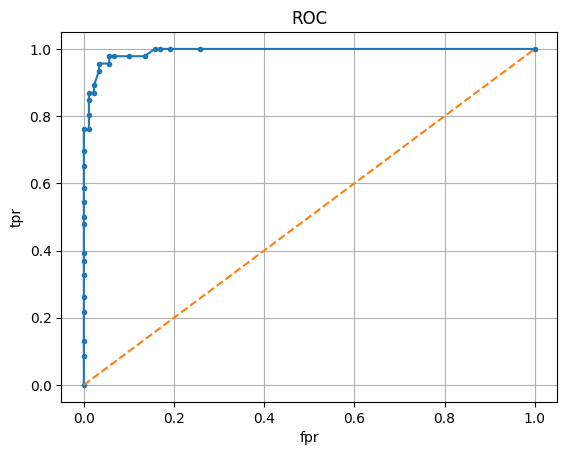

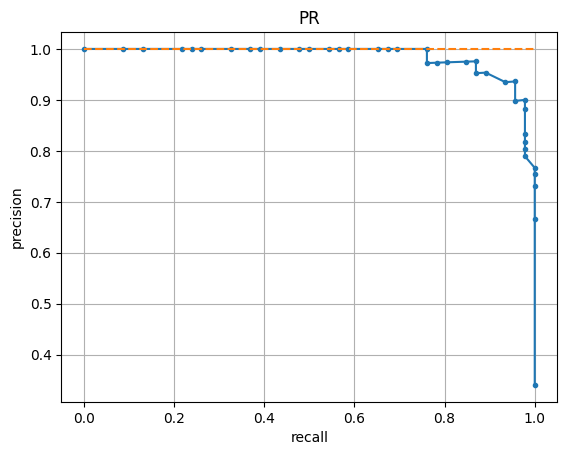



                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        43
Iris-versicolor       0.80      0.98      0.88        46
 Iris-virginica       0.97      0.76      0.85        46

       accuracy                           0.91       135
      macro avg       0.93      0.91      0.91       135
   weighted avg       0.92      0.91      0.91       135



In [77]:
p3 = pd.read_csv('/content/IRIS.csv')
display(p3.head())
y = p3[['species']]
x = p3.drop(['species'],axis=1)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.9, random_state=2)
m = RFC().fit(x_train,y_train)
print(m.score(x_test,y_test))

proba = m.predict_proba(x_test)
y_test_2_ = pd.get_dummies(y_test,dtype=np.float64)
y_test_2 = y_test_2_.values
for i in range(proba.shape[1]):
  print(f'Класс: {y_test_2_.columns[i]}')
  # Выводим ROC кривую
  plt.title("ROC")
  plt.xlabel("fpr")
  plt.ylabel("tpr")
  plt.grid('ON')
  plt.plot(*roc(y_test_2[:,i], proba[:, i])[:-1], marker='.')
  plt.plot([0, 1], [0, 1], linestyle='--')
  plt.show()

  print()

  # Выводим PR кривую
  plt.title("PR")
  plt.grid('ON')
  plt.xlabel("recall")
  plt.ylabel("precision")
  precision, recall = prc(y_test_2[:,i], proba[:, i])[:-1]
  plt.plot(recall,precision, marker='.')
  no_skill = len(y[y==1]) / len(y)
  plt.plot([0, 1], [no_skill, no_skill], linestyle='--')
  plt.show()

  print()
  #print(report(y_test_2[:,i],proba[:, i]))


print()
print(report(y_test,m.predict(x_test)))

#roc_auc_score(y_test, proba[:, 1])

#6 Используйте для построения кривых библиотеку yellowbrick.

In [ ]:
p3 = pd.read_csv('/content/IRIS.csv')
display(p3.head())
y = p3[['species']]
x = p3.drop(['species'],axis=1)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.9, random_state=2)
m = RFC().fit(x_train,y_train)
print(m.score(x_test,y_test))



vis = ROCAUC(RFC(), classes = y['species'].unique())
vis.fit(x_train,y_train)
vis.score(x_test, y_test)
vis.show()


vis = PrecisionRecallCurve(RFC(), classes = y['species'].unique(),per_class=True)
vis.fit(x_train,y_train)
vis.score(x_test, y_test)
vis.show()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


/usr/local/lib/python3.11/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
